# Character-level representation cho NER trên noisy text (WNUT 17)

**Câu hỏi nghiên cứu:** Character representation có giúp mô hình nhận diện entity unseen và rare tốt hơn không?

Notebook dùng dữ liệu `dany0407/wnut_17`, PyTorch và các mô hình huấn luyện hoàn toàn từ đầu (không pretrained embeddings/model). So sánh: (1) word-BiLSTM-Softmax, (2) word-BiLSTM-CRF, (3) word+character-CNN-BiLSTM-CRF. Mô hình (2) đồng thời là ablation tắt character của (3), giữ nguyên word encoder và CRF.

Entity **unseen** có surface form chưa xuất hiện trong entity train; **rare** xuất hiện 1–2 lần trong train; **frequent** xuất hiện ít nhất 3 lần. Tần suất chỉ được tính từ train. Báo cáo entity-level exact-span micro-F1 và bootstrap theo câu trên test để so sánh mô hình character với ablation. Bootstrap phản ánh độ bất định do lấy mẫu test, không thay thế nhiều lần chạy với seed khác nhau.

Nếu chưa cài package, chạy cell setup. Nếu máy không có CUDA, notebook vẫn chạy CPU; giảm `EPOCHS`/`BATCH_SIZE` để thử nhanh. Thời gian tùy cấu hình máy.

In [1]:
# Cài nếu thiếu: %pip install datasets pandas matplotlib scikit-learn
import os, random, time, collections
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4, os.cpu_count() or 1))

# Siêu tham số (giảm EPOCHS/BATCH_SIZE nếu chỉ muốn chạy thử nhanh trên CPU).
EPOCHS = 30
PATIENCE = 8            # early stopping theo validation entity-F1
BATCH_SIZE = 32
LR = 2e-3
WORD_DIM = 100
CHAR_DIM = 30
CHAR_FILTERS = 50
MAX_CHARS = 30          # cắt token quá dài (URL, ...) để tiết kiệm bộ nhớ
HIDDEN_DIM = 128
DROPOUT = 0.5
WORD_UNK_ALPHA = 1.0    # p(thay từ bằng <UNK> khi train) = alpha / (count + alpha)
print(f'PyTorch {torch.__version__} | device={DEVICE}')
if DEVICE.type == 'cuda': print(torch.cuda.get_device_name(0))
# Bộ siêu tham số mặc định; mục 4b sẽ tìm bộ tốt hơn cho từng mô hình.
DEFAULT_HP = dict(lr=LR, hidden_dim=HIDDEN_DIM, dropout=DROPOUT, word_dim=WORD_DIM, char_dim=CHAR_DIM,
                  char_filters=CHAR_FILTERS, word_unk_alpha=WORD_UNK_ALPHA, batch_size=BATCH_SIZE)

PyTorch 2.11.0+cu130 | device=cuda
Tesla T4


## 1. Nạp và kiểm tra dữ liệu

Ưu tiên validation/test có sẵn; chỉ tách validation từ train theo seed nếu dataset không cung cấp. Giữ nguyên tokenization và tag sequence của nguồn dữ liệu.

In [2]:
ds = load_dataset('dany0407/wnut_17')
print(ds)
print('Columns:', ds[next(iter(ds.keys()))].column_names)
print('Features:', ds[next(iter(ds.keys()))].features)
train_raw = ds['train']
test_raw = ds['test']
if 'validation' in ds:
    valid_raw = ds['validation']
elif 'dev' in ds:
    valid_raw = ds['dev']
else:
    split = train_raw.train_test_split(test_size=0.1, seed=SEED)
    train_raw, valid_raw = split['train'], split['test']

def find_column(columns, candidates):
    for name in candidates:
        if name in columns: return name
    raise KeyError(f'Không tìm thấy cột trong {columns}; cần một trong {candidates}')

token_col = find_column(train_raw.column_names, ['tokens', 'words', 'text'])
tag_col = find_column(train_raw.column_names, ['ner_tags', 'tags', 'labels'])
tag_feature = train_raw.features[tag_col]
tag_names = getattr(getattr(tag_feature, 'feature', tag_feature), 'names', None)
if tag_names is None:
    raise ValueError('Không đọc được danh sách nhãn từ feature; kiểm tra schema của dataset.')
print(f'Splits: train={len(train_raw)}, validation={len(valid_raw)}, test={len(test_raw)}')
print('Tags:', tag_names)
print('Example:', train_raw[0][token_col][:12], train_raw[0][tag_col][:12])

README.md:   0%|          | 0.00/926 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  308kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 66.6kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3394 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1009 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1287 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 3394
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1009
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1287
    })
})
Columns: ['id', 'tokens', 'ner_tags']
Features: {'id': Value('string'), 'tokens': List(Value('string')), 'ner_tags': List(ClassLabel(names=['O', 'B-corporation', 'I-corporation', 'B-creative-work', 'I-creative-work', 'B-group', 'I-group', 'B-location', 'I-location', 'B-person', 'I-person', 'B-product', 'I-product']))}
Splits: train=3394, validation=1009, test=1287
Tags: ['O', 'B-corporation', 'I-corporation', 'B-creative-work', 'I-creative-work', 'B-group', 'I-group', 'B-location', 'I-location', 'B-person', 'I-person', 'B-product', 'I-product']
Example: ['@paulwalk', 'It', "'s", 'the', 'view', 'from', 'where', 'I', "'m", 'living', 'for', 'two'] [0, 0, 0, 0, 0, 0, 0, 0, 0, 0

## 2. Chuẩn hóa nhãn và định nghĩa unseen/rare

Entity surface là chuỗi token ghép bằng khoảng trắng, chuẩn hóa lowercase chỉ để đếm tần suất. Nhãn BIO được chuyển thành span; parser chịu được tiền tố I không hợp lệ bằng cách bắt đầu span mới. Báo cáo riêng span không có trong train và span có tần suất 1–2.

In [3]:
def normalize_split(split):
    rows = []
    for row in split:
        tokens = [str(x) for x in row[token_col]]
        raw_tags = row[tag_col]
        tags = [tag_names[int(x)] if not isinstance(x, str) else x for x in raw_tags]
        if len(tokens) != len(tags):
            raise ValueError(f'Token/tag length mismatch: {len(tokens)} != {len(tags)}')
        rows.append({'tokens': tokens, 'tags': tags})
    return rows

train = normalize_split(train_raw)
valid = normalize_split(valid_raw)
test = normalize_split(test_raw)
# Lấy từ schema của dataset (không chỉ từ train) để tránh KeyError nếu valid/test có nhãn chưa xuất hiện trong train.
tag_set = list(tag_names)
tag2id = {tag: i for i, tag in enumerate(tag_set)}
id2tag = {i: tag for tag, i in tag2id.items()}
if 'O' not in tag2id: raise ValueError('Nhãn O không có trong danh sách nhãn.')

def parse_spans(tags):
    spans, start, active_type = [], None, None
    def close(end):
        nonlocal start, active_type
        if start is not None: spans.append((start, end, active_type))
        start, active_type = None, None
    for i, tag in enumerate(list(tags) + ['O']):
        if tag == 'O' or tag == '':
            close(i); continue
        if '-' in tag:
            prefix, entity_type = tag.split('-', 1)
        else:
            prefix, entity_type = 'B', tag
        if prefix in ('B', 'S', 'U'):
            close(i)
            if prefix in ('S', 'U'):
                spans.append((i, i + 1, entity_type))
            else:
                start, active_type = i, entity_type
        elif prefix in ('I', 'E', 'L'):
            if start is None or active_type != entity_type:
                close(i); start, active_type = i, entity_type
            if prefix in ('E', 'L'):
                close(i + 1)
        else:
            close(i); start, active_type = i, entity_type
    return spans

def surface(tokens, span):
    a, b, _ = span
    return ' '.join(tokens[a:b])

entity_freq = collections.Counter(
    surface(row['tokens'], span).casefold()
    for row in train for span in parse_spans(row['tags'])
)
def entity_group(tokens, span):
    count = entity_freq[surface(tokens, span).casefold()]
    return 'unseen' if count == 0 else ('rare (1-2)' if count <= 2 else 'frequent (3+)')

print('Tag vocabulary:', tag2id)
print('Entity occurrences in train:', sum(entity_freq.values()))
group_counts = collections.Counter(entity_group(row['tokens'], s) for row in test for s in parse_spans(row['tags']))
print('Gold test entity counts:', dict(group_counts))

Tag vocabulary: {'O': 0, 'B-corporation': 1, 'I-corporation': 2, 'B-creative-work': 3, 'I-creative-work': 4, 'B-group': 5, 'I-group': 6, 'B-location': 7, 'I-location': 8, 'B-person': 9, 'I-person': 10, 'B-product': 11, 'I-product': 12}
Entity occurrences in train: 1975
Gold test entity counts: {'unseen': 1055, 'rare (1-2)': 22, 'frequent (3+)': 2}


## 3. Vocabulary, batching và character encoder

Word vocabulary và character vocabulary chỉ học từ train; word OOV dùng `<UNK>`. Khi huấn luyện, từ hiếm bị thay ngẫu nhiên bằng `<UNK>` (xác suất α/(count+α)) để embedding `<UNK>` thực sự được học; nếu không, mọi từ OOV lúc test sẽ nhận một vector ngẫu nhiên chưa từng được huấn luyện. Character CNN mã hóa từng token, ghép vector ký tự với word embedding rồi đưa vào BiLSTM.

In [4]:
PAD_WORD, UNK_WORD, PAD_CHAR, UNK_CHAR = '<PAD>', '<UNK>', '<PAD_CHAR>', '<UNK_CHAR>'
word_counts = collections.Counter(tok for row in train for tok in row['tokens'])
word2id = {PAD_WORD: 0, UNK_WORD: 1}
for word in word_counts: word2id.setdefault(word, len(word2id))
char2id = {PAD_CHAR: 0, UNK_CHAR: 1}
for row in train:
    for token in row['tokens']:
        for char in token: char2id.setdefault(char, len(char2id))
PAD_TAG = -100

# Vì mọi từ train đều có trong vocab, <UNK> sẽ không bao giờ được học nếu không thay từ ngẫu nhiên khi train
# (lúc test, từ OOV khi đó nhận một vector ngẫu nhiên chưa huấn luyện). Từ càng hiếm càng hay bị thay bằng <UNK>.
def make_unk_prob(alpha):
    prob = torch.zeros(len(word2id))
    for word, idx in word2id.items():
        if idx > 1: prob[idx] = alpha / (word_counts[word] + alpha)
    return prob

class NERDataset(Dataset):
    def __init__(self, rows): self.rows = rows
    def __len__(self): return len(self.rows)
    def __getitem__(self, idx):
        row = self.rows[idx]
        words = [word2id.get(w, word2id[UNK_WORD]) for w in row['tokens']]
        tags = [tag2id[t] for t in row['tags']]
        chars = [[char2id.get(c, char2id[UNK_CHAR]) for c in w[:MAX_CHARS]] or [char2id[UNK_CHAR]] for w in row['tokens']]
        return words, chars, tags

def collate_batch(batch):
    lengths = torch.tensor([len(x[0]) for x in batch], dtype=torch.long)
    max_tokens = int(lengths.max())
    max_chars = max(1, max(len(chars) for _, char_seq, _ in batch for chars in char_seq))
    words = torch.zeros(len(batch), max_tokens, dtype=torch.long)
    tags = torch.full((len(batch), max_tokens), PAD_TAG, dtype=torch.long)
    chars = torch.zeros(len(batch), max_tokens, max_chars, dtype=torch.long)
    char_lengths = torch.zeros(len(batch), max_tokens, dtype=torch.long)
    for i, (word_ids, char_seq, tag_ids) in enumerate(batch):
        n = len(word_ids); words[i, :n] = torch.tensor(word_ids); tags[i, :n] = torch.tensor(tag_ids)
        for j, char_ids in enumerate(char_seq):
            chars[i, j, :len(char_ids)] = torch.tensor(char_ids)
            char_lengths[i, j] = len(char_ids)
    return words, chars, char_lengths, tags, lengths

def make_loader(rows, shuffle=False, seed=SEED, batch_size=None):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(NERDataset(rows), batch_size=batch_size or BATCH_SIZE, shuffle=shuffle,
                      collate_fn=collate_batch, generator=generator, num_workers=0)

train_loader, valid_loader, test_loader = make_loader(train, True), make_loader(valid), make_loader(test)

def oov_rate(rows):
    toks = [t for row in rows for t in row['tokens']]
    return sum(t not in word2id for t in toks) / len(toks)
print(f'word vocab={len(word2id):,}; char vocab={len(char2id):,}; labels={len(tag2id)}')
print(f'Token OOV rate: valid={oov_rate(valid):.1%}, test={oov_rate(test):.1%}')
print('Train batches:', len(train_loader), '| Example batch shapes:', [tuple(x.shape) for x in next(iter(train_loader))])

word vocab=14,880; char vocab=94; labels=13
Token OOV rate: valid=16.7%, test=21.9%
Train batches: 107 | Example batch shapes: [(32, 33), (32, 33, 30), (32, 33), (32, 33), (32,)]


## 4. Mô hình huấn luyện từ đầu

CRF tối ưu chuỗi nhãn hợp lệ trên toàn câu. Word-BiLSTM-Softmax là baseline 1; Word-BiLSTM-CRF là baseline 2 và ablation character-off; Word+Char-CNN-BiLSTM-CRF là mô hình đề xuất. Mỗi mô hình dùng đúng một loss chuẩn (CRF: negative log-likelihood; softmax: cross-entropy), không class weight hay loss phụ, để khác biệt giữa các mô hình chỉ đến từ kiến trúc.

In [5]:
class LinearChainCRF(nn.Module):
    def __init__(self, num_tags):
        super().__init__()
        self.transitions = nn.Parameter(torch.empty(num_tags, num_tags))
        self.start = nn.Parameter(torch.empty(num_tags)); self.end = nn.Parameter(torch.empty(num_tags))
        nn.init.uniform_(self.transitions, -0.1, 0.1)
        nn.init.uniform_(self.start, -0.1, 0.1); nn.init.uniform_(self.end, -0.1, 0.1)

    def nll(self, emissions, tags, lengths):
        batch, steps, _ = emissions.shape
        safe_tags = tags.masked_fill(tags.eq(PAD_TAG), 0)
        gold = self.start[safe_tags[:, 0]] + emissions[:, 0].gather(1, safe_tags[:, 0:1]).squeeze(1)
        for t in range(1, steps):
            active = (lengths > t)
            step_score = self.transitions[safe_tags[:, t-1], safe_tags[:, t]] + emissions[:, t].gather(1, safe_tags[:, t:t+1]).squeeze(1)
            gold = gold + step_score * active
        last_tags = safe_tags[torch.arange(batch, device=tags.device), lengths - 1]
        gold = gold + self.end[last_tags]
        alpha = self.start + emissions[:, 0]
        for t in range(1, steps):
            scores = alpha.unsqueeze(2) + self.transitions.unsqueeze(0) + emissions[:, t].unsqueeze(1)
            next_alpha = torch.logsumexp(scores, dim=1)
            alpha = torch.where((lengths > t).unsqueeze(1), next_alpha, alpha)
        partition = torch.logsumexp(alpha + self.end, dim=1)
        return (partition - gold).mean()

    def decode(self, emissions, lengths):
        paths = []
        for i, length in enumerate(lengths.tolist()):
            score = self.start + emissions[i, 0]
            backpointers = []
            for t in range(1, length):
                candidates = score.unsqueeze(1) + self.transitions
                best_score, best_prev = candidates.max(dim=0)
                score = best_score + emissions[i, t]
                backpointers.append(best_prev)
            tag = int((score + self.end).argmax())
            path = [tag]
            for pointer in reversed(backpointers):
                tag = int(pointer[tag]); path.append(tag)
            paths.append(list(reversed(path)))
        return paths

class NERModel(nn.Module):
    def __init__(self, use_char, use_crf, hp=None):
        super().__init__()
        hp = {**DEFAULT_HP, **(hp or {})}
        self.use_char, self.use_crf = use_char, use_crf
        self.word_embedding = nn.Embedding(len(word2id), hp['word_dim'], padding_idx=word2id[PAD_WORD])
        input_dim = hp['word_dim']
        if use_char:
            self.char_embedding = nn.Embedding(len(char2id), hp['char_dim'], padding_idx=char2id[PAD_CHAR])
            self.char_conv = nn.Conv1d(hp['char_dim'], hp['char_filters'], kernel_size=3, padding=1)
            input_dim += hp['char_filters']
        self.input_dropout = nn.Dropout(hp['dropout'])
        self.encoder = nn.LSTM(input_dim, hp['hidden_dim'], batch_first=True, bidirectional=True)
        self.output_dropout = nn.Dropout(hp['dropout'])
        self.classifier = nn.Linear(hp['hidden_dim'] * 2, len(tag2id))
        self.crf = LinearChainCRF(len(tag2id)) if use_crf else None

    def forward(self, words, chars, char_lengths, lengths):
        features = [self.word_embedding(words)]
        if self.use_char:
            b, t, c = chars.shape
            embedded = self.char_embedding(chars.reshape(b*t, c)).transpose(1, 2)
            convolved = torch.relu(self.char_conv(embedded)).transpose(1, 2)           # (b*t, c, filters), >= 0
            positions = torch.arange(c, device=chars.device).unsqueeze(0)
            mask = positions < char_lengths.reshape(-1, 1)
            # relu >= 0 nên fill 0 an toàn cho max-pool; token padding (không có ký tự) cho vector 0 thay vì -3e38.
            convolved = convolved.masked_fill(~mask.unsqueeze(-1), 0.0)
            features.append(convolved.max(dim=1).values.reshape(b, t, -1))
        inputs = self.input_dropout(torch.cat(features, dim=-1))
        packed = nn.utils.rnn.pack_padded_sequence(inputs, lengths.cpu(), batch_first=True, enforce_sorted=False)
        encoded, _ = self.encoder(packed)
        encoded, _ = nn.utils.rnn.pad_packed_sequence(encoded, batch_first=True, total_length=words.shape[1])
        return self.classifier(self.output_dropout(encoded))

    def loss(self, emissions, tags, lengths):
        # Mỗi mô hình dùng đúng một loss chuẩn (không class weight, không loss phụ) để so sánh công bằng.
        if self.use_crf: return self.crf.nll(emissions, tags, lengths)
        return nn.functional.cross_entropy(emissions.reshape(-1, emissions.shape[-1]), tags.reshape(-1), ignore_index=PAD_TAG)

    def predict(self, emissions, lengths):
        if self.use_crf: return self.crf.decode(emissions, lengths)
        return [emissions[i, :n].argmax(-1).tolist() for i, n in enumerate(lengths.tolist())]

@torch.no_grad()
def evaluate_loss(model, loader):
    model.eval(); total, count = 0.0, 0
    for batch in loader:
        words, chars, char_lengths, tags, lengths = [x.to(DEVICE) for x in batch]
        loss = model.loss(model(words, chars, char_lengths, lengths), tags, lengths)
        total += float(loss) * len(lengths); count += len(lengths)
    return total / max(count, 1)

@torch.no_grad()
def evaluate_entity_f1(model, loader):
    model.eval(); tp = fp = fn = 0
    for batch in loader:
        words, chars, char_lengths, tags, lengths = [x.to(DEVICE) for x in batch]
        paths = model.predict(model(words, chars, char_lengths, lengths), lengths)
        for i, path in enumerate(paths):
            n = int(lengths[i])
            gold_tags = [id2tag[int(x)] for x in tags[i, :n].tolist()]
            pred_tags = [id2tag[x] for x in path]
            gold_spans, pred_spans = set(parse_spans(gold_tags)), set(parse_spans(pred_tags))
            tp += len(gold_spans & pred_spans); fp += len(pred_spans - gold_spans); fn += len(gold_spans - pred_spans)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return 2 * precision * recall / (precision + recall) if precision + recall else 0.0

def train_model(name, use_char, use_crf, hp=None, seed=SEED, epochs=None, patience=None, verbose=True):
    hp = {**DEFAULT_HP, **(hp or {})}
    epochs, patience = epochs or EPOCHS, patience or PATIENCE
    set_seed(seed)                                   # cùng seed, cùng thứ tự shuffle cho mọi mô hình
    loader = make_loader(train, shuffle=True, seed=seed, batch_size=hp['batch_size'])
    model = NERModel(use_char, use_crf, hp).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=hp['lr'])
    unk_prob_dev = make_unk_prob(hp['word_unk_alpha']).to(DEVICE)
    best_f1, best_loss, best_state, stale, history = -1.0, float('inf'), None, 0, []
    start_time = time.time()
    for epoch in range(1, epochs + 1):
        model.train(); total, count = 0.0, 0
        for words, chars, char_lengths, tags, lengths in loader:
            words, chars, char_lengths, tags, lengths = [x.to(DEVICE) for x in (words, chars, char_lengths, tags, lengths)]
            drop = torch.rand(words.shape, device=DEVICE) < unk_prob_dev[words]      # PAD/UNK có xác suất 0
            words_in = words.masked_fill(drop, word2id[UNK_WORD])
            optimizer.zero_grad(set_to_none=True)
            loss = model.loss(model(words_in, chars, char_lengths, lengths), tags, lengths)
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 5.0); optimizer.step()
            total += float(loss.detach()) * len(lengths); count += len(lengths)
        valid_loss = evaluate_loss(model, valid_loader)
        valid_f1 = evaluate_entity_f1(model, valid_loader)
        history.append({'epoch': epoch, 'train_loss': total/max(count,1), 'valid_loss': valid_loss, 'valid_entity_f1': valid_f1})
        if verbose:
            print(f'{name}: epoch {epoch}/{epochs} train_loss={total/max(count,1):.4f} valid_loss={valid_loss:.4f} valid_entity_f1={valid_f1:.4f}')
        if valid_f1 > best_f1 or (valid_f1 == best_f1 and valid_loss < best_loss):
            best_f1, best_loss, stale = valid_f1, valid_loss, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
            if stale >= patience: break
    if best_state is None: raise RuntimeError(f'{name} training produced no checkpoint')
    model.load_state_dict(best_state)
    if verbose:
        print(f'{name}: restored best validation checkpoint (valid_entity_f1={best_f1:.4f}); elapsed={time.time()-start_time:.1f}s')
    return model, history

print('Model components initialized successfully.')

Model components initialized successfully.


## 4b. Tối ưu siêu tham số

Random search riêng cho từng mô hình với **cùng ngân sách và cùng dãy cấu hình ngẫu nhiên** (lần thử đầu luôn là bộ mặc định), để so sánh công bằng. Chỉ dùng **validation entity-F1** (hòa thì chọn validation loss thấp hơn) để chọn; tập test không được dùng ở bước này. Mỗi lần thử huấn luyện ngắn (`TUNE_EPOCHS`, `TUNE_PATIENCE`), sau đó mô hình tốt nhất được huấn luyện lại đầy đủ ở mục 5.

Không gian tìm kiếm: learning rate (log-uniform), hidden size, dropout, chiều word embedding, α của word-`<UNK>` và batch size; thêm chiều char embedding và số filter CNN (chỉ có tác dụng với mô hình có character). Một seed và validation nhỏ nên việc chọn cấu hình vẫn có nhiễu; tăng `TUNE_TRIALS` nếu có thời gian. Đặt `RUN_TUNING = False` để bỏ qua và dùng bộ mặc định.

In [6]:
RUN_TUNING = True
TUNE_TRIALS = 8        # số cấu hình thử cho mỗi mô hình (tăng nếu có GPU)
TUNE_EPOCHS = 15
TUNE_PATIENCE = 4

configs = {
    'Baseline 1: Word-BiLSTM-Softmax': (False, False),
    'Baseline 2 / Ablation: Word-BiLSTM-CRF': (False, True),
    'Proposed: Word+CharCNN-BiLSTM-CRF': (True, True),
}

def sample_hp(rng):
    # Luôn lấy đủ mọi tham số theo cùng thứ tự để dãy cấu hình giống nhau giữa các mô hình.
    return dict(
        lr=float(10 ** rng.uniform(np.log10(5e-4), np.log10(5e-3))),
        hidden_dim=int(rng.choice([64, 128, 256])),
        dropout=float(rng.choice([0.3, 0.5, 0.6])),
        word_dim=int(rng.choice([50, 100, 200])),
        word_unk_alpha=float(rng.choice([0.5, 1.0, 2.0])),
        batch_size=int(rng.choice([16, 32, 64])),
        char_dim=int(rng.choice([25, 30, 50])),
        char_filters=int(rng.choice([30, 50, 100])),
    )

def tune_model(name, use_char, use_crf):
    rng = np.random.default_rng(SEED)
    rows = []
    for k in range(TUNE_TRIALS):
        hp = dict(DEFAULT_HP) if k == 0 else sample_hp(rng)
        if k == 0: sample_hp(rng)                      # giữ đồng bộ dãy ngẫu nhiên
        _, hist = train_model(name, use_char, use_crf, hp=hp, epochs=TUNE_EPOCHS, patience=TUNE_PATIENCE, verbose=False)
        best = max(hist, key=lambda h: (h['valid_entity_f1'], -h['valid_loss']))
        rows.append({'model': name, 'trial': k, **hp, 'best_epoch': best['epoch'],
                     'valid_entity_f1': best['valid_entity_f1'], 'valid_loss': best['valid_loss']})
        print(f"{name} | trial {k+1}/{TUNE_TRIALS} | valid_entity_f1={best['valid_entity_f1']:.4f} | "
              f"lr={hp['lr']:.4g} hidden={hp['hidden_dim']} dropout={hp['dropout']} bs={hp['batch_size']}")
    return rows

best_hp, tuning_rows = {}, []
if RUN_TUNING:
    for name, (use_char, use_crf) in configs.items():
        tuning_rows += tune_model(name, use_char, use_crf)
    tuning_df = pd.DataFrame(tuning_rows)
    for name in configs:
        sub_df = tuning_df[tuning_df.model == name].sort_values(['valid_entity_f1', 'valid_loss'], ascending=[False, True])
        top = sub_df.iloc[0]
        best_hp[name] = {k: (int(top[k]) if k in ('hidden_dim', 'word_dim', 'batch_size', 'char_dim', 'char_filters') else float(top[k]))
                         for k in DEFAULT_HP}
    display(tuning_df.sort_values(['model', 'valid_entity_f1'], ascending=[True, False]).round(4))
    tuning_df.to_csv('wnut17_hyperparameter_search.csv', index=False)
else:
    best_hp = {name: dict(DEFAULT_HP) for name in configs}
for name, hp in best_hp.items(): print(name, '->', hp)

Baseline 1: Word-BiLSTM-Softmax | trial 1/8 | valid_entity_f1=0.0356 | lr=0.002 hidden=128 dropout=0.5 bs=32
Baseline 1: Word-BiLSTM-Softmax | trial 2/8 | valid_entity_f1=0.0000 | lr=0.004727 hidden=64 dropout=0.6 bs=64
Baseline 1: Word-BiLSTM-Softmax | trial 3/8 | valid_entity_f1=0.0000 | lr=0.00141 hidden=128 dropout=0.5 bs=64
Baseline 1: Word-BiLSTM-Softmax | trial 4/8 | valid_entity_f1=0.0024 | lr=0.001388 hidden=256 dropout=0.5 bs=32
Baseline 1: Word-BiLSTM-Softmax | trial 5/8 | valid_entity_f1=0.0024 | lr=0.003362 hidden=64 dropout=0.5 bs=64
Baseline 1: Word-BiLSTM-Softmax | trial 6/8 | valid_entity_f1=0.0428 | lr=0.003909 hidden=256 dropout=0.6 bs=16
Baseline 1: Word-BiLSTM-Softmax | trial 7/8 | valid_entity_f1=0.0000 | lr=0.0005531 hidden=128 dropout=0.3 bs=64
Baseline 1: Word-BiLSTM-Softmax | trial 8/8 | valid_entity_f1=0.0116 | lr=0.001059 hidden=256 dropout=0.6 bs=32
Baseline 2 / Ablation: Word-BiLSTM-CRF | trial 1/8 | valid_entity_f1=0.0429 | lr=0.002 hidden=128 dropout=0.5

,model,trial,lr,hidden_dim,dropout,word_dim,char_dim,char_filters,word_unk_alpha,batch_size,best_epoch,valid_entity_f1,valid_loss
5,Baseline 1: Word-BiLSTM-Softmax,5,0.0039,256,0.6,200,30,50,2.0,16,15,0.0428,0.4656
0,Baseline 1: Word-BiLSTM-Softmax,0,0.0020,128,0.5,100,30,50,1.0,32,14,0.0356,0.3850
7,Baseline 1: Word-BiLSTM-Softmax,7,0.0011,256,0.6,100,50,30,0.5,32,12,0.0116,0.3898
3,Baseline 1: Word-BiLSTM-Softmax,3,0.0014,256,0.5,50,50,30,0.5,32,6,0.0024,0.3921
4,Baseline 1: Word-BiLSTM-Softmax,4,0.0034,64,0.5,50,30,30,2.0,64,15,0.0024,0.4107
1,Baseline 1: Word-BiLSTM-Softmax,1,0.0047,64,0.6,200,30,30,2.0,64,3,0.0000,0.4197
2,Baseline 1: Word-BiLSTM-Softmax,2,0.0014,128,0.5,50,30,50,2.0,64,14,0.0000,0.4012
6,Baseline 1: Word-BiLSTM-Softmax,6,0.0006,128,0.3,200,50,50,2.0,64,14,0.0000,0.4039
13,Baseline 2 / Ablation: Word-BiLSTM-CRF,5,0.0039,256,0.6,200,30,50,2.0,16,12,0.0454,4.6907
8,Baseline 2 / Ablation: Word-BiLSTM-CRF,0,0.0020,128,0.5,100,30,50,1.0,32,14,0.0429,4.6113


Baseline 1: Word-BiLSTM-Softmax -> {'lr': 0.003909229124243194, 'hidden_dim': 256, 'dropout': 0.6, 'word_dim': 200, 'char_dim': 30, 'char_filters': 50, 'word_unk_alpha': 2.0, 'batch_size': 16}
Baseline 2 / Ablation: Word-BiLSTM-CRF -> {'lr': 0.003909229124243194, 'hidden_dim': 256, 'dropout': 0.6, 'word_dim': 200, 'char_dim': 30, 'char_filters': 50, 'word_unk_alpha': 2.0, 'batch_size': 16}
Proposed: Word+CharCNN-BiLSTM-CRF -> {'lr': 0.0013879831797587651, 'hidden_dim': 256, 'dropout': 0.5, 'word_dim': 50, 'char_dim': 50, 'char_filters': 30, 'word_unk_alpha': 0.5, 'batch_size': 32}


## 5. Huấn luyện ba mô hình và đánh giá

Dùng cùng split, seed, word vocabulary, optimizer và tiêu chí chọn checkpoint (validation entity-F1, hòa thì chọn validation loss thấp hơn). Mọi embedding/encoder được khởi tạo ngẫu nhiên. Mỗi mô hình dùng bộ siêu tham số tốt nhất tìm được ở mục 4b.

In [7]:
models, histories = {}, {}
for name, (use_char, use_crf) in configs.items():
    models[name], histories[name] = train_model(name, use_char, use_crf, hp=best_hp[name])

@torch.no_grad()
def predict_rows(model, rows):
    model.eval(); predictions = []
    for batch in make_loader(rows):
        words, chars, char_lengths, _, lengths = [x.to(DEVICE) for x in batch]
        emissions = model(words, chars, char_lengths, lengths)
        predictions.extend([[id2tag[x] for x in path] for path in model.predict(emissions, lengths)])
    return predictions

predictions = {name: predict_rows(model, test) for name, model in models.items()}
assert all(len(p) == len(test) for p in predictions.values())
print('Prediction complete:', {name: len(p) for name, p in predictions.items()})

Baseline 1: Word-BiLSTM-Softmax: epoch 1/30 train_loss=0.3622 valid_loss=0.3969 valid_entity_f1=0.0000
Baseline 1: Word-BiLSTM-Softmax: epoch 2/30 train_loss=0.2805 valid_loss=0.4138 valid_entity_f1=0.0000
Baseline 1: Word-BiLSTM-Softmax: epoch 3/30 train_loss=0.2612 valid_loss=0.4189 valid_entity_f1=0.0000
Baseline 1: Word-BiLSTM-Softmax: epoch 4/30 train_loss=0.2413 valid_loss=0.4019 valid_entity_f1=0.0024
Baseline 1: Word-BiLSTM-Softmax: epoch 5/30 train_loss=0.2337 valid_loss=0.4171 valid_entity_f1=0.0024
Baseline 1: Word-BiLSTM-Softmax: epoch 6/30 train_loss=0.2187 valid_loss=0.4154 valid_entity_f1=0.0161
Baseline 1: Word-BiLSTM-Softmax: epoch 7/30 train_loss=0.2162 valid_loss=0.4151 valid_entity_f1=0.0179
Baseline 1: Word-BiLSTM-Softmax: epoch 8/30 train_loss=0.2040 valid_loss=0.4116 valid_entity_f1=0.0092
Baseline 1: Word-BiLSTM-Softmax: epoch 9/30 train_loss=0.1983 valid_loss=0.4113 valid_entity_f1=0.0183
Baseline 1: Word-BiLSTM-Softmax: epoch 10/30 train_loss=0.1961 valid_loss

## 6. Bằng chứng thực nghiệm: exact-span F1 theo độ phổ biến

Một span đúng khi khớp chính xác start, end và loại entity. Precision/recall/F1 tính micro. Theo nhóm, gold được phân vào nhóm theo tần suất surface form train; predicted span được phân nhóm tương tự để tính FP nhất quán. Support là số gold span trong nhóm. Lưu ý: nhóm rare/frequent có support rất nhỏ trên test, nên F1 các nhóm này rất nhiễu.

In [8]:
GROUPS = ['all', 'unseen', 'rare (1-2)', 'frequent (3+)']
def sentence_counts(tokens, gold_tags, pred_tags):
    gold = parse_spans(gold_tags); pred = parse_spans(pred_tags)
    gold_by_group = collections.defaultdict(set); pred_by_group = collections.defaultdict(set)
    for span in gold: gold_by_group[entity_group(tokens, span)].add(span)
    for span in pred: pred_by_group[entity_group(tokens, span)].add(span)
    result = {}
    for group in GROUPS[1:]:
        g, p = gold_by_group[group], pred_by_group[group]
        result[group] = (len(g & p), len(p - g), len(g - p), len(g))
    g_all, p_all = set(gold), set(pred)
    result['all'] = (len(g_all & p_all), len(p_all - g_all), len(g_all - p_all), len(g_all))
    return result

def aggregate_metrics(model_predictions):
    totals = {g: np.zeros(4, dtype=np.int64) for g in GROUPS}
    per_sentence = []
    for row, pred_tags in zip(test, model_predictions):
        counts = sentence_counts(row['tokens'], row['tags'], pred_tags)
        per_sentence.append(counts)
        for group, values in counts.items(): totals[group] += values
    metrics = {}
    for group, (tp, fp, fn, support) in totals.items():
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
        metrics[group] = {'precision': precision, 'recall': recall, 'f1': f1, 'support': int(support), 'tp': int(tp), 'fp': int(fp), 'fn': int(fn)}
    return metrics, per_sentence

all_metrics, sentence_level = {}, {}
for name, pred in predictions.items(): all_metrics[name], sentence_level[name] = aggregate_metrics(pred)
score_rows = []
for name, group_metrics in all_metrics.items():
    for group in GROUPS:
        m = group_metrics[group]
        score_rows.append({'model': name, 'entity_group': group, 'precision': m['precision'], 'recall': m['recall'], 'F1': m['f1'], 'support': m['support']})
results = pd.DataFrame(score_rows)
display(results.round(4))
results.to_csv('wnut17_entity_metrics.csv', index=False)

first_model = next(iter(all_metrics))
for group in GROUPS[1:]:
    n = all_metrics[first_model][group]['support']
    if n < 30:
        print(f'Cảnh báo: nhóm "{group}" chỉ có {n} gold span trên test -> F1 của nhóm này rất nhiễu, không nên dùng để kết luận.')

,model,entity_group,precision,recall,F1,support
0,Baseline 1: Word-BiLSTM-Softmax,all,0.1165,0.0334,0.0519,1079
1,Baseline 1: Word-BiLSTM-Softmax,unseen,0.1126,0.0322,0.0501,1055
2,Baseline 1: Word-BiLSTM-Softmax,rare (1-2),0.4000,0.0909,0.1481,22
3,Baseline 1: Word-BiLSTM-Softmax,frequent (3+),0.0000,0.0000,0.0000,2
4,Baseline 2 / Ablation: Word-BiLSTM-CRF,all,0.1738,0.0491,0.0766,1079
5,Baseline 2 / Ablation: Word-BiLSTM-CRF,unseen,0.1694,0.0483,0.0752,1055
6,Baseline 2 / Ablation: Word-BiLSTM-CRF,rare (1-2),0.5000,0.0909,0.1538,22
7,Baseline 2 / Ablation: Word-BiLSTM-CRF,frequent (3+),0.0000,0.0000,0.0000,2
8,Proposed: Word+CharCNN-BiLSTM-CRF,all,0.2153,0.1094,0.1451,1079
9,Proposed: Word+CharCNN-BiLSTM-CRF,unseen,0.2165,0.1118,0.1475,1055


Cảnh báo: nhóm "rare (1-2)" chỉ có 22 gold span trên test -> F1 của nhóm này rất nhiễu, không nên dùng để kết luận.
Cảnh báo: nhóm "frequent (3+)" chỉ có 2 gold span trên test -> F1 của nhóm này rất nhiễu, không nên dùng để kết luận.


## 7. Ablation và bootstrap CI cho chênh lệch F1

Ablation chính là mô hình word-only CRF (tắt character; cùng word BiLSTM và CRF với proposed). Bootstrap resample câu có hoàn lại, tính lại micro-F1 mỗi lần; CI percentile 95% cho `F1(character) - F1(word-only CRF)`. CI không bao gồm biến thiên do huấn luyện lại.

,entity_group,F1_word+char,F1_word_only_CRF,delta_F1,support,bootstrap_95%_CI,bootstrap_P(delta>0)
0,all,0.1451,0.0766,0.0685,1079,"[0.0439, 0.0929]",1.0
1,unseen,0.1475,0.0752,0.0723,1055,"[0.0489, 0.0974]",1.0
2,rare (1-2),0.0000,0.1538,-0.1538,22,"[-0.3529, 0.0000]",0.0
3,frequent (3+),0.0000,0.0000,0.0000,2,"[0.0000, 0.0000]",0.0


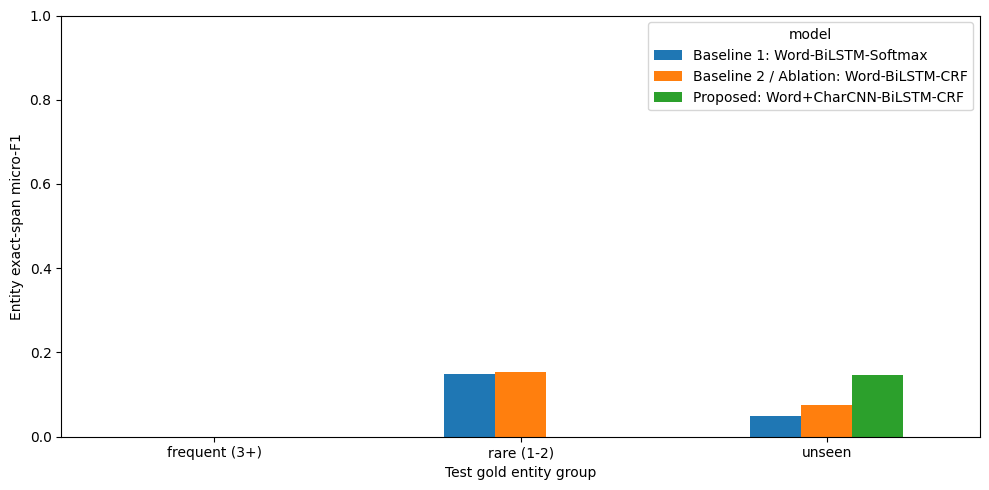

In [9]:
PROPOSED = 'Proposed: Word+CharCNN-BiLSTM-CRF'
ABLATION = 'Baseline 2 / Ablation: Word-BiLSTM-CRF'

def counts_array(per_sentence, group):
    """Mảng (n_câu, 3) gồm tp, fp, fn của từng câu cho một nhóm entity."""
    return np.array([s[group][:3] for s in per_sentence], dtype=np.int64)

def f1_from_totals(totals):
    """micro-F1 từ mảng (..., 3) = tp, fp, fn; xử lý chia 0 và hỗ trợ batch."""
    tp, fp, fn = (totals[..., k].astype(float) for k in range(3))
    zeros = np.zeros_like(tp)
    p = np.divide(tp, tp + fp, out=zeros.copy(), where=(tp + fp) > 0)
    r = np.divide(tp, tp + fn, out=zeros.copy(), where=(tp + fn) > 0)
    return np.divide(2 * p * r, p + r, out=zeros.copy(), where=(p + r) > 0)

def bootstrap_delta(group, n_boot=1000, seed=SEED, a_name=PROPOSED, b_name=ABLATION, chunk=100):
    """Bootstrap theo câu (có hoàn lại), cùng chỉ số câu cho cả hai mô hình (paired)."""
    rng = np.random.default_rng(seed)
    a = counts_array(sentence_level[a_name], group); b = counts_array(sentence_level[b_name], group)
    n = len(a); deltas = np.empty(n_boot)
    for start in range(0, n_boot, chunk):
        idx = rng.integers(0, n, size=(min(chunk, n_boot - start), n))
        deltas[start:start + len(idx)] = f1_from_totals(a[idx].sum(axis=1)) - f1_from_totals(b[idx].sum(axis=1))
    point = all_metrics[a_name][group]['f1'] - all_metrics[b_name][group]['f1']
    low, high = np.quantile(deltas, [0.025, 0.975])
    return point, float(low), float(high), float(np.mean(deltas > 0))

bootstrap_cache = {group: bootstrap_delta(group) for group in GROUPS}   # tính một lần, dùng lại ở mục 8

ablation_rows = []
for group in GROUPS:
    delta, low, high, prob_positive = bootstrap_cache[group]
    ablation_rows.append({'entity_group': group, 'F1_word+char': all_metrics[PROPOSED][group]['f1'],
                          'F1_word_only_CRF': all_metrics[ABLATION][group]['f1'],
                          'delta_F1': delta, 'support': all_metrics[PROPOSED][group]['support'], 'bootstrap_95%_CI': f'[{low:.4f}, {high:.4f}]',
                          'bootstrap_P(delta>0)': prob_positive})
ablation_results = pd.DataFrame(ablation_rows)
display(ablation_results.round(4))
ablation_results.to_csv('wnut17_ablation_bootstrap.csv', index=False)

plot_df = results[results.entity_group.isin(['unseen', 'rare (1-2)', 'frequent (3+)'])]
ax = plot_df.pivot(index='entity_group', columns='model', values='F1').plot(kind='bar', figsize=(10, 5))
ax.set_ylabel('Entity exact-span micro-F1'); ax.set_xlabel('Test gold entity group'); ax.set_ylim(0, 1)
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 8. Phân tích lỗi và kết luận dựa trên số liệu

Liệt kê lỗi span (bỏ sót, gán sai ranh giới/loại, dự đoán thừa) trên một số câu test; đồng thời tổng hợp FP/FN theo nhóm unseen/rare/frequent. Kết luận cuối cùng được sinh từ metric thực tế, không giả định character luôn có lợi.

In [10]:
def span_text(tokens, span): return f"{' '.join(tokens[span[0]:span[1]])} [{span[2]}]"
def collect_errors(pred_tags):
    errors = []
    for sent_id, (row, predicted) in enumerate(zip(test, pred_tags)):
        gold_spans, pred_spans = set(parse_spans(row['tags'])), set(parse_spans(predicted))
        missed, extra = gold_spans - pred_spans, pred_spans - gold_spans
        if not missed and not extra: continue
        for span in sorted(missed):
            errors.append({'sentence_id': sent_id, 'error': 'FN/missed or boundary/type mismatch', 'entity': span_text(row['tokens'], span),
                           'group': entity_group(row['tokens'], span), 'context': ' '.join(row['tokens'])[:220]})
        for span in sorted(extra):
            errors.append({'sentence_id': sent_id, 'error': 'FP/spurious or boundary/type mismatch', 'entity': span_text(row['tokens'], span),
                           'group': entity_group(row['tokens'], span), 'context': ' '.join(row['tokens'])[:220]})
    return errors

proposed_name = PROPOSED
error_rows = collect_errors(predictions[proposed_name])
error_df = pd.DataFrame(error_rows)
if len(error_df):
    display(error_df.head(20))
    display(error_df.groupby(['group', 'error']).size().rename('count').reset_index())
    error_df.to_csv('wnut17_error_examples.csv', index=False)
else:
    print('Không có lỗi span trên test — hãy kiểm tra kích thước test và parser nhãn.')

char = all_metrics[PROPOSED]
word = all_metrics[ABLATION]
MIN_SUPPORT = 30
for group in ['unseen', 'rare (1-2)', 'all']:
    delta, low, high, _ = bootstrap_cache[group]
    n = char[group]['support']
    sign = 'dương' if delta > 0 else ('âm' if delta < 0 else 'bằng 0')
    if n < MIN_SUPPORT:
        evidence = f'support chỉ {n} < {MIN_SUPPORT}, quá ít để kết luận'
    elif low > 0 or high < 0:
        evidence = 'CI không chứa 0'
    else:
        evidence = 'CI chứa 0, chưa có bằng chứng chắc chắn về khác biệt'
    print(f"{group}: Word+Char F1={char[group]['f1']:.4f} (n={n}), word-only CRF F1={word[group]['f1']:.4f}; "
          f"Δ={delta:+.4f} ({sign}), 95% CI [{low:+.4f}, {high:+.4f}] -> {evidence}.")

print('\nKết luận: Character representation có giúp unseen/rare hay không phải dựa vào Δ-F1 và bootstrap CI ngay phía trên. '
      'CI chứa 0 nghĩa là thí nghiệm này chưa đủ bằng chứng để kết luận cải thiện; không diễn giải là hai mô hình tương đương. '
      'Nhóm có support nhỏ (rare, frequent) chỉ mang tính tham khảo. '
      'Xem các FN/FP và nhóm lỗi để nhận diện lỗi do viết biến thể/OOV, ranh giới entity, nhãn mơ hồ hoặc entity không đủ ngữ cảnh. '
      'Hạn chế: một seed và một split; bootstrap chỉ lượng hóa biến thiên lấy mẫu test, và surface-form matching có thể đánh đồng entity khác ngữ nghĩa.')
print('Saved: wnut17_entity_metrics.csv, wnut17_ablation_bootstrap.csv, wnut17_error_examples.csv')

,sentence_id,error,entity,group,context
0,0,FN/missed or boundary/type mismatch,Sonmarg [location],unseen,& gt ; * The soldier was killed when another a...
1,0,FP/spurious or boundary/type mismatch,The soldier [location],unseen,& gt ; * The soldier was killed when another a...
2,0,FP/spurious or boundary/type mismatch,Sonmarg [person],unseen,& gt ; * The soldier was killed when another a...
3,1,FN/missed or boundary/type mismatch,Waltengoo Nar [location],unseen,& gt ; * Police last week evacuated 80 village...
4,1,FP/spurious or boundary/type mismatch,Police [location],unseen,& gt ; * Police last week evacuated 80 village...
5,1,FP/spurious or boundary/type mismatch,Waltengoo Nar [person],unseen,& gt ; * Police last week evacuated 80 village...
6,2,FP/spurious or boundary/type mismatch,The army [location],unseen,& gt ; * The army on Thursday recovered the bo...
7,4,FN/missed or boundary/type mismatch,Avalanche Rescue Teams [group],unseen,The bodies of the soldiers were recovered afte...
8,4,FN/missed or boundary/type mismatch,ART [group],unseen,The bodies of the soldiers were recovered afte...
9,4,FP/spurious or boundary/type mismatch,Avalanche Rescue Teams [product],unseen,The bodies of the soldiers were recovered afte...


,group,error,count
0,frequent (3+),FN/missed or boundary/type mismatch,2
1,rare (1-2),FN/missed or boundary/type mismatch,22
2,rare (1-2),FP/spurious or boundary/type mismatch,3
3,unseen,FN/missed or boundary/type mismatch,937
4,unseen,FP/spurious or boundary/type mismatch,427


unseen: Word+Char F1=0.1475 (n=1055), word-only CRF F1=0.0752; Δ=+0.0723 (dương), 95% CI [+0.0489, +0.0974] -> CI không chứa 0.
rare (1-2): Word+Char F1=0.0000 (n=22), word-only CRF F1=0.1538; Δ=-0.1538 (âm), 95% CI [-0.3529, +0.0000] -> support chỉ 22 < 30, quá ít để kết luận.
all: Word+Char F1=0.1451 (n=1079), word-only CRF F1=0.0766; Δ=+0.0685 (dương), 95% CI [+0.0439, +0.0929] -> CI không chứa 0.

Kết luận: Character representation có giúp unseen/rare hay không phải dựa vào Δ-F1 và bootstrap CI ngay phía trên. CI chứa 0 nghĩa là thí nghiệm này chưa đủ bằng chứng để kết luận cải thiện; không diễn giải là hai mô hình tương đương. Nhóm có support nhỏ (rare, frequent) chỉ mang tính tham khảo. Xem các FN/FP và nhóm lỗi để nhận diện lỗi do viết biến thể/OOV, ranh giới entity, nhãn mơ hồ hoặc entity không đủ ngữ cảnh. Hạn chế: một seed và một split; bootstrap chỉ lượng hóa biến thiên lấy mẫu test, và surface-form matching có thể đánh đồng entity khác ngữ nghĩa.
Saved: wnut17_entity_metric